# Задача данного notebook проанализировать какие есть выбросы, где они находиться и как избавиться от них.

### Данный notebook должен выдать notebook должен выдать csv, где в данных мы уверены, что нету какого-то ужасного ужаса

### Загрузка данных

In [104]:
import pandas as pd
from datetime import timedelta

df = pd.read_csv("data/listings.csv")
df = df.sort_values("listing_id", ascending=True)
df = df.drop_duplicates(keep = "first")
display(df.shape)
df.head()

(15274, 18)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
14697,100004,10001,private,NaN,Велосипед горный с документами,3200,2800,3,289.0,Moscow,2026-08-01 07:07:09,2026-08-31 07:07:09,истёк срок,298,8,2,12,35
10109,100009,10005,private,Детские товары,Самокат детский как новый,3950,3950,6,100.0,Moscow,2026-08-01 08:06:10,2026-08-11 13:23:30,снято продавцом,237,8,1,12,66
12896,100012,10011,private,Детские товары,Манеж,2050,2050,6,107.0,Казань,2026-08-01 08:13:44,2026-08-05 20:27:25,снято продавцом,23,1,0,1,9
3356,100013,10012,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,12680,12680,8,84.0,Москва,2026-08-01 08:24:58,2026-08-05 14:14:26,снято продавцом,32,1,0,2,18
12498,100018,10013,private,Мебель и интерьер,Стеллаж как новый,12990,12990,6,173.0,Москва,2026-08-01 08:29:46,2026-08-03 08:46:37,снято продавцом,0,0,0,0,0


### Убираем строчки, где время _published_at_ > _closed_at_

In [105]:
delta_time = pd.to_timedelta(df['closed_at'].apply(lambda x: pd.to_datetime(x).timestamp()) - df['published_at'].apply(lambda x: pd.to_datetime(x).timestamp()), unit='s')

df["delta"] = delta_time
listing_ids_of_bad_time = df.loc[~(df["delta"] > timedelta(0)), "listing_id"].to_list()
df = df[df["delta"] > timedelta(0)]
df = df.drop("delta", axis=1)
display(df.shape)

(15234, 18)

### Посторим графики и посмотрим на данные. Цель - понять, где есть впринципе выбросы и где есть cлишком больших выбросы

##### Смотрим по этим столбцам: 
* price 
* current_price
* photos_count
* description_length
* views_total
* favorites_total
* phone_views_total
* chats_total
* messages_total

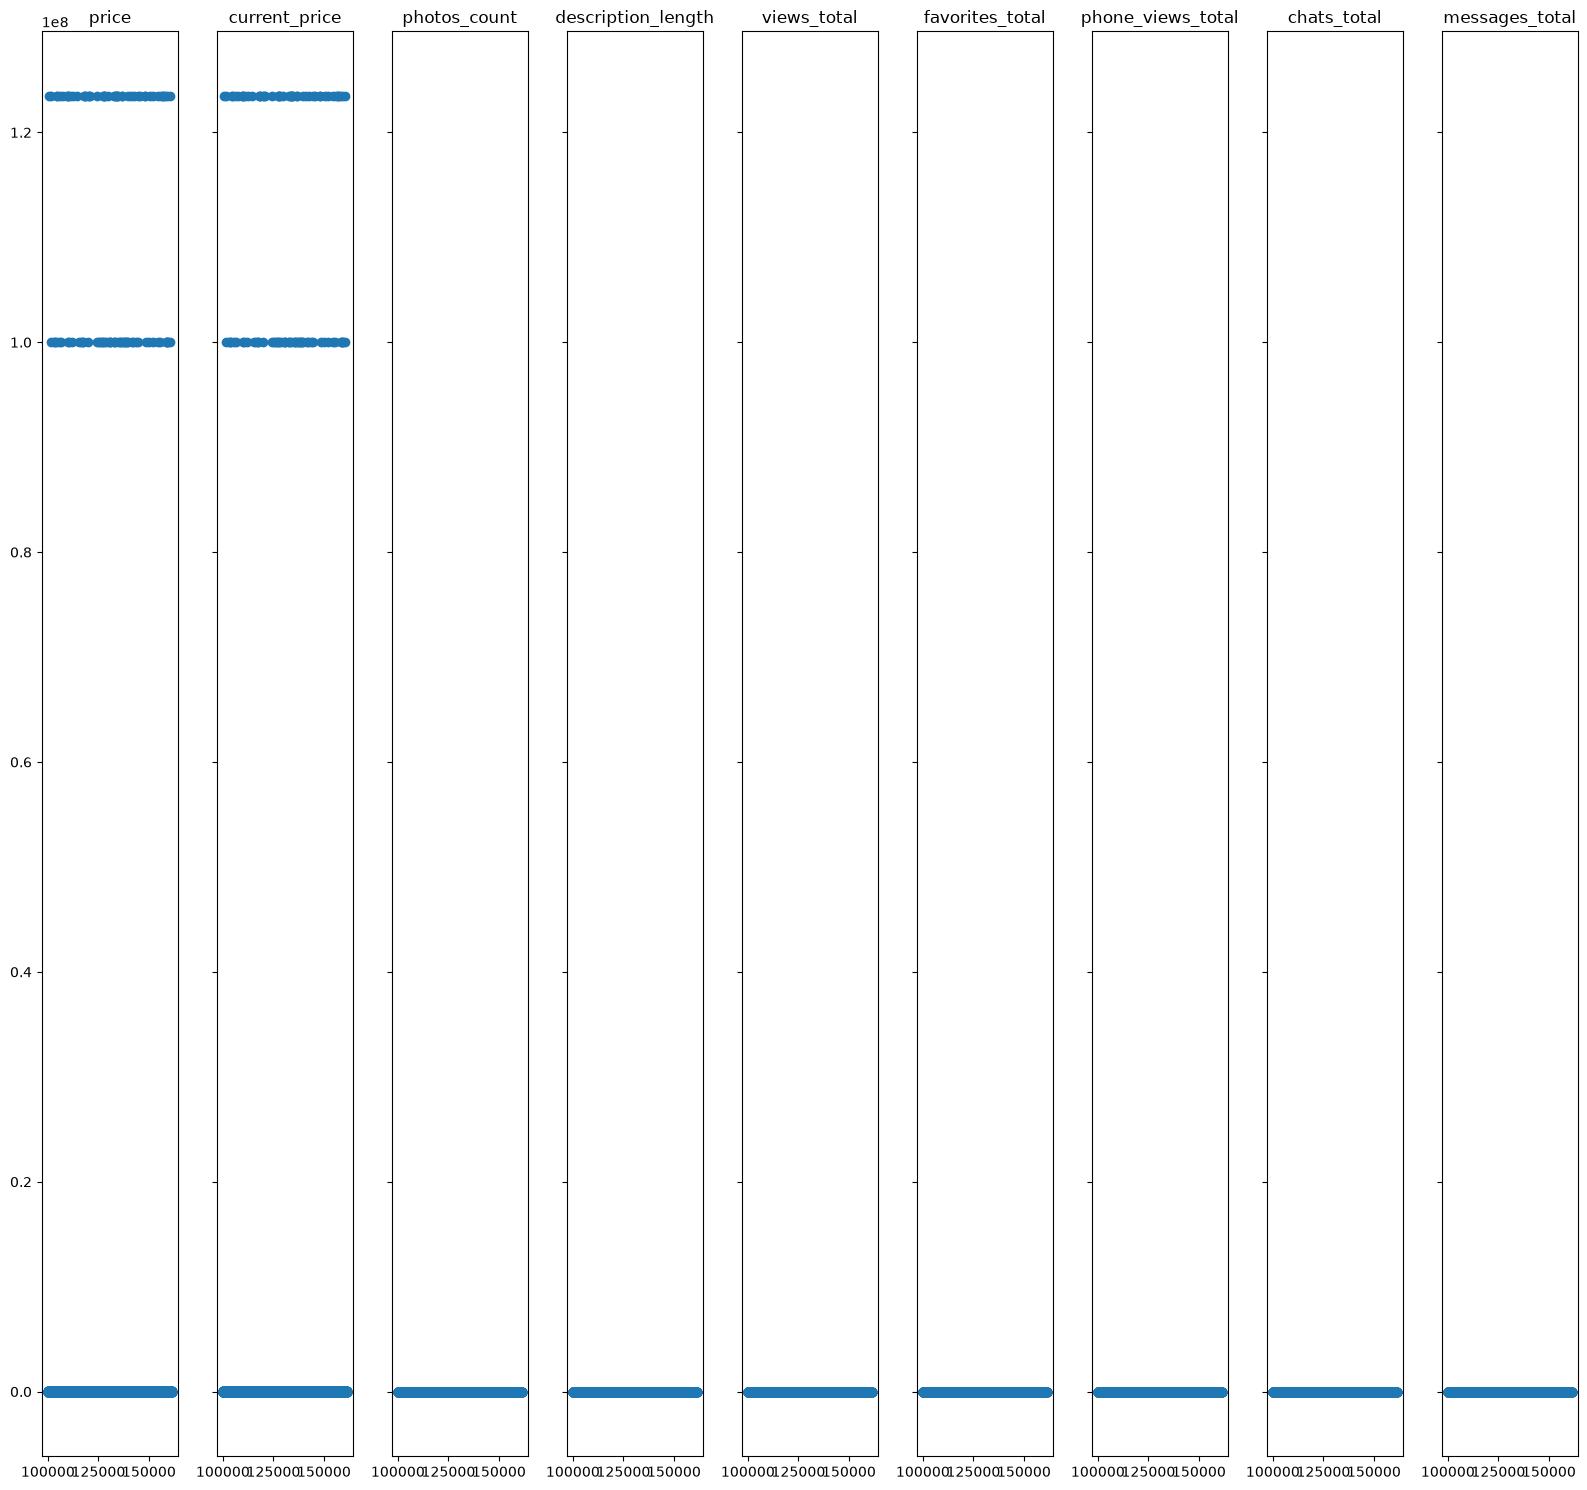

In [106]:
import matplotlib.pyplot as plt

values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]

fig, axes = plt.subplots(
    1, len(values), figsize=(16, 15), sharey=True, squeeze=False
)


for ax, value in zip(axes[0], values):
    y = df[value]

    ax.scatter(df["listing_id"], y)
    ax.set_title(f"{value}")

fig.tight_layout()
plt.show()

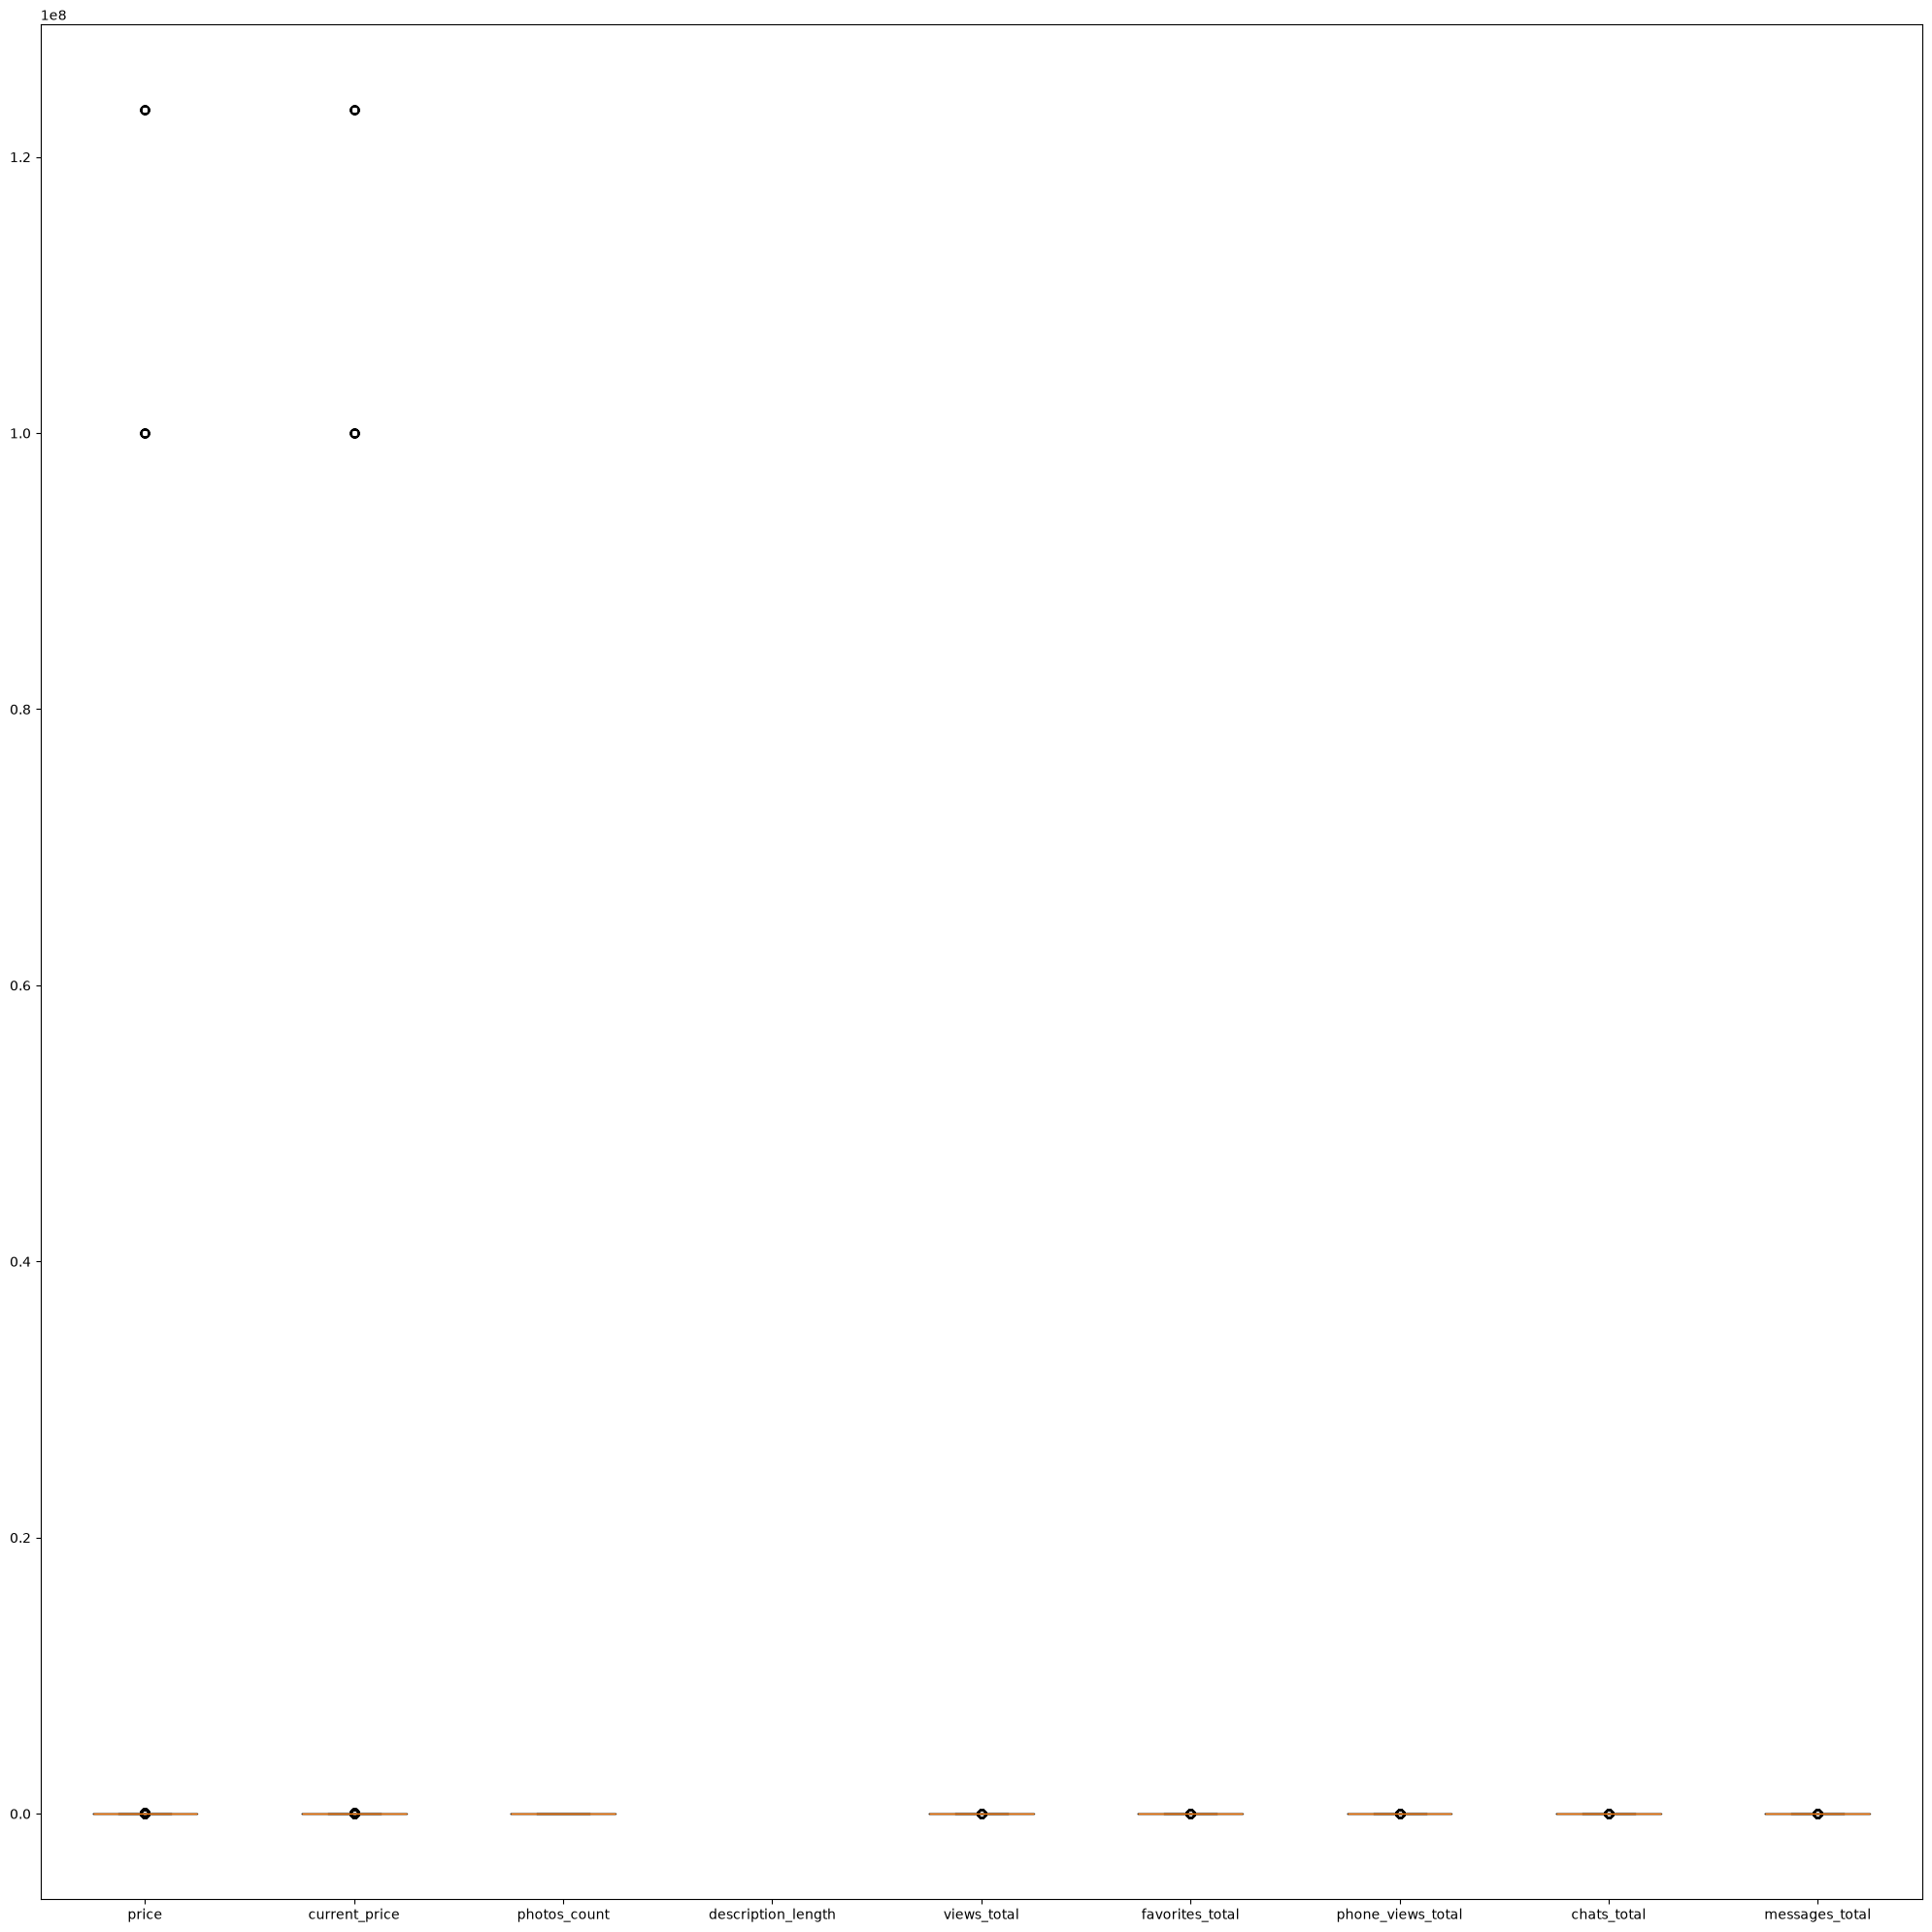

In [107]:
values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]
    
data = [
    df[value]
    for value in values
]

plt.figure(figsize=(20, 20))
plt.boxplot(data, tick_labels=values)

plt.tight_layout()
plt.show()

### Формируем отдельную csv, со слишком большими выбросами

In [108]:
df_vibros = df[(df["price"] > 0.2*10**8) | (df["current_price"] > 0.2*10**8)]
display(df_vibros.shape)
#df_vibros.to_csv("vibros.csv", index=False, encoding="utf-8")
df_vibros

(98, 18)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
2978,100352,10374,private,Одежда и обувь,Рюкзак городской в хорошем состоянии,123456789,123456789,5,66.0,Новосибирск,2026-08-01 17:40:25,2026-08-06 18:03:07,снято продавцом,55,3,0,1,14
8015,101374,11376,business,Спорт и отдых,Беговая дорожка отличное состояние,123456789,123456789,5,768.0,Санкт-Петербург,2026-08-02 18:30:31,2026-09-01 18:30:31,истёк срок,238,6,0,15,53
5608,101453,11471,private,Электроника,Наушники беспроводные новый,99999999,99999999,5,50.0,Новосибирск,2026-08-02 19:47:31,2026-08-05 17:57:12,снято продавцом,35,1,0,2,23
9551,102833,12850,private,Спорт и отдых,Гантели разборные отличное состояние,99999999,99999999,6,50.0,Санкт-Петербург,2026-08-04 18:20:36,2026-08-08 23:07:37,снято продавцом,36,2,1,0,0
13249,103662,11693,private,Одежда и обувь,Куртка зимняя в хорошем состоянии,99999999,99999999,6,138.0,Москва,2026-08-05 17:59:10,2026-08-06 21:03:57,снято продавцом,25,1,0,2,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1664,158937,32792,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,123456789,123456789,3,53.0,Москва,2026-10-03 23:48:34,2026-10-06 08:18:40,снято продавцом,34,1,0,2,4
3555,159062,40694,private,Спорт и отдых,Беговая дорожка торг,99999999,99999999,3,169.0,Москва,2026-10-04 10:42:05,2026-10-05 19:37:49,снято продавцом,11,0,0,1,8
14069,159591,18365,business,Одежда и обувь,Пальто шерстяное новый,99999999,99999999,7,765.0,Казань,2026-10-04 17:53:52,2026-11-03 17:53:52,истёк срок,248,10,2,10,50
9171,160202,28310,private,Одежда и обувь,Рюкзак городской,99999999,99999999,2,103.0,екатеринбург,2026-10-05 10:16:43,2026-10-11 13:38:14,снято продавцом,60,2,1,2,19


### Чистим основной df

In [109]:
indexes_high = df_vibros["listing_id"]
display(df.shape)
df = df[~df["listing_id"].isin(indexes_high)]
display(df.shape)

(15234, 18)

(15136, 18)

## Смотрим на распределение данных уже без слишком больших выбросов и посмотрим какие есть слишком маленькие данные(где priсe очень низкий)

In [110]:
med_price = df["price"].median()
med_price_curr = df["current_price"].median()

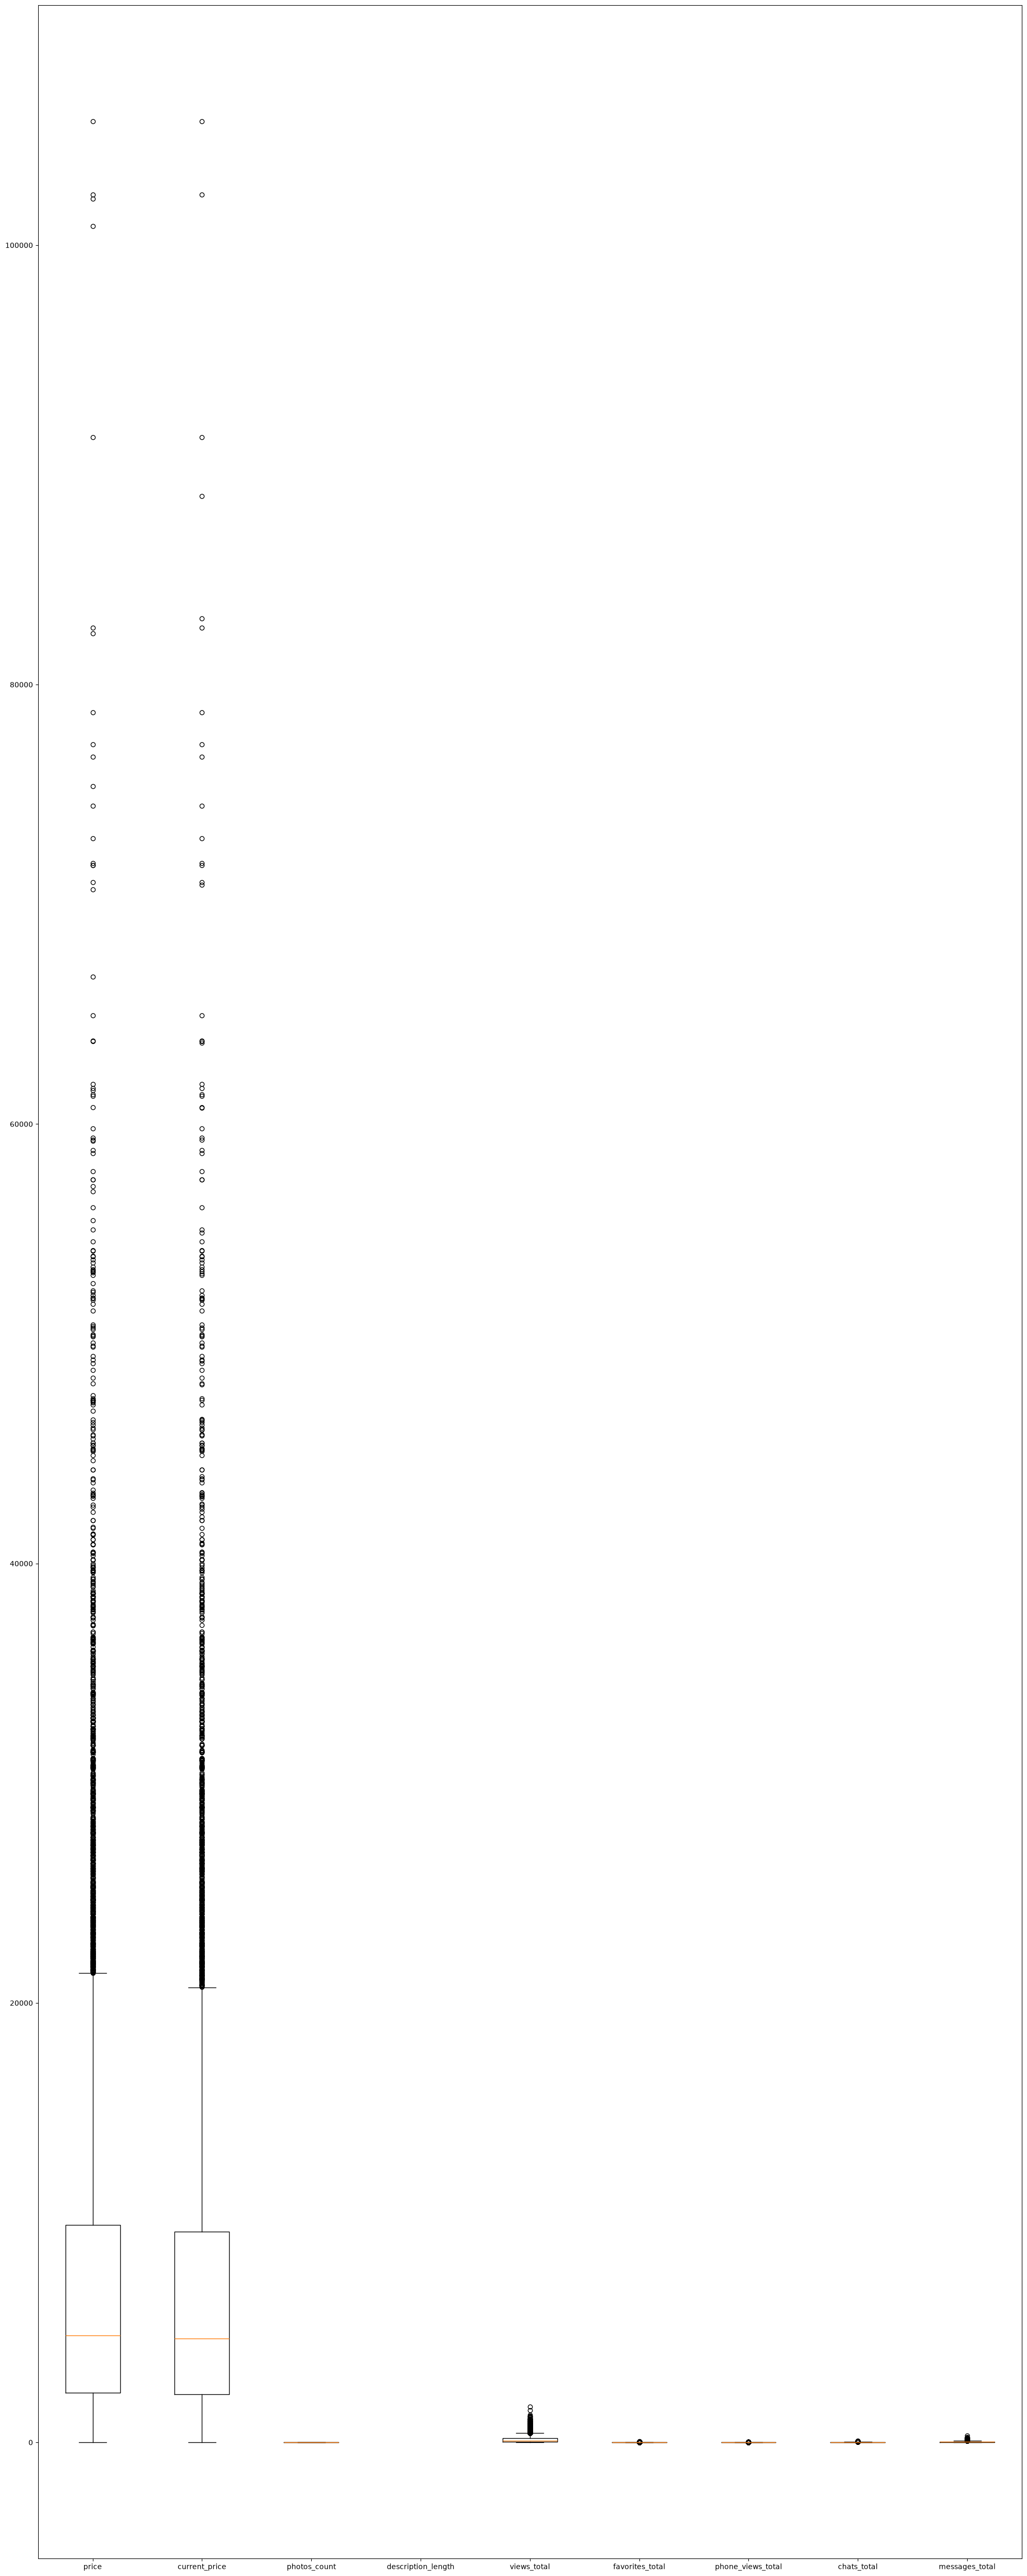

In [111]:
import matplotlib.ticker as ticker

values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]
    
data = [
    df[value]
    for value in values
]

plt.figure(figsize=(20, 50))
plt.boxplot(data, tick_labels=values)

ax.grid(True)
plt.tight_layout()
plt.show()

In [112]:
df_low_med = df[(df["price"] < med_price) | (df["current_price"] < med_price_curr)]
df_low_med_price = df_low_med.sort_values(by="price", ascending=True)
df_low_med_price_curr = df_low_med.sort_values(by="current_price", ascending=True)

In [113]:
df_low_med_price.head(30)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
3896,108789,16103,business,Электроника,Колонка JBL,0,0,2,564.0,Москва,2026-08-11 21:56:46,2026-09-10 21:56:46,истёк срок,288,4,3,12,41
11942,138876,10106,private,Одежда и обувь,Ботинки кожаные,0,0,3,107.0,Санкт-Петербург,2026-09-14 15:58:41,2026-10-14 15:58:41,истёк срок,78,4,0,4,15
3821,156577,12850,private,Бытовая техника,Посудомоечная машина,0,0,6,159.0,Санкт-Петербург,2026-10-01 20:33:43,2026-10-31 20:33:43,истёк срок,417,11,8,7,11
13079,124713,28461,private,Мебель и интерьер,Шкаф-купе срочно,0,0,1,NaN,Москва,2026-08-31 08:57:49,2026-09-02 14:33:13,снято продавцом,11,0,1,0,0
11321,154733,24192,private,Бытовая техника,Пылесос Dyson,0,0,0,56.0,Санкт-Петербург,2026-09-30 10:26:33,2026-10-16 12:40:35,снято продавцом,58,2,0,3,14
2909,156112,36750,private,Запчасти и аксессуары,Бампер передний,0,0,3,26.0,Москва,2026-10-01 15:42:17,2026-10-09 08:06:38,снято продавцом,26,0,1,2,14
3890,126937,29577,private,Мебель и интерьер,Люстра,0,0,6,17.0,Москва,2026-09-02 16:35:39,2026-09-06 19:46:51,снято продавцом,14,0,0,1,13
1629,137194,33863,private,Запчасти и аксессуары,Шины зимние R16 срочно,0,0,3,72.0,Нижний Новгород,2026-09-12 21:26:04,2026-09-24 07:51:58,снято продавцом,40,1,0,1,17
10463,128343,30270,private,Электроника,Фотоаппарат Canon срочно,0,0,5,98.0,Краснодар,2026-09-03 22:24:46,2026-09-16 10:13:14,снято продавцом,151,4,1,7,24
8325,155518,27412,private,Запчасти и аксессуары,Бампер передний срочно,0,0,10,254.0,Москва,2026-09-30 21:07:05,2026-10-15 18:35:49,снято продавцом,245,8,6,4,24


In [114]:
df_low_med_price_curr.head(30)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
4181,110362,18178,private,Детские товары,Радионяня с документами,0,0,4,318.0,Москва,2026-08-13 20:02:25,2026-08-24 19:53:10,снято продавцом,130,5,3,4,34
7101,138924,16221,private,NaN,Сапоги зимние новый,0,0,0,67.0,Санкт-Петербург,2026-09-14 16:48:14,2026-09-16 21:07:20,снято продавцом,14,0,0,1,2
13533,146331,18236,private,Бытовая техника,Робот-пылесос,0,0,5,73.0,Казань,2026-09-21 19:55:06,2026-10-21 19:55:06,истёк срок,301,13,4,9,19
15405,110579,14546,private,Спорт и отдых,Спальный мешок в хорошем состоянии,0,0,3,NaN,Нижний Новгород,2026-08-13 22:32:47,2026-08-22 17:13:33,снято продавцом,34,2,0,1,7
2549,143658,36148,private,Электроника,Наушники беспроводные в хорошем состоянии,0,0,3,17.0,Москва,2026-09-18 23:33:28,2026-10-18 23:33:28,истёк срок,205,8,0,10,27
3587,110782,15971,private,Электроника,Колонка JBL новый,0,0,3,89.0,Самара,2026-08-14 10:43:44,2026-08-27 12:16:04,снято продавцом,266,8,4,9,46
8335,111237,16005,private,Детские товары,Кроватка детская,0,0,3,238.0,Казань,2026-08-14 19:18:20,2026-08-21 20:03:50,снято продавцом,47,1,1,4,23
1962,128375,20645,private,Электроника,Наушники беспроводные торг,0,0,1,177.0,Moscow,2026-09-03 22:58:21,2026-10-03 22:58:21,истёк срок,392,7,3,16,51
10463,128343,30270,private,Электроника,Фотоаппарат Canon срочно,0,0,5,98.0,Краснодар,2026-09-03 22:24:46,2026-09-16 10:13:14,снято продавцом,151,4,1,7,24
8419,111282,12165,private,Бытовая техника,Кондиционер,0,0,4,NaN,Москва,2026-08-14 20:05:07,2026-08-25 21:56:23,снято продавцом,82,3,1,2,25


In [115]:
df_low = df[(df["price"] < 20) | (df["current_price"] < 20)]
display(df_low.shape)
df_low = df_low.sort_values(by="price", ascending=False)
low_listing_ids = df_low["listing_id"]

(85, 18)

### Убираем слишком низкие значения из df, т.е. где price = 0 или 1

In [116]:
display(df.shape)
df = df[~df["listing_id"].isin(low_listing_ids)]
df

(15136, 18)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
14697,100004,10001,private,NaN,Велосипед горный с документами,3200,2800,3,289.0,Moscow,2026-08-01 07:07:09,2026-08-31 07:07:09,истёк срок,298,8,2,12,35
10109,100009,10005,private,Детские товары,Самокат детский как новый,3950,3950,6,100.0,Moscow,2026-08-01 08:06:10,2026-08-11 13:23:30,снято продавцом,237,8,1,12,66
12896,100012,10011,private,Детские товары,Манеж,2050,2050,6,107.0,Казань,2026-08-01 08:13:44,2026-08-05 20:27:25,снято продавцом,23,1,0,1,9
3356,100013,10012,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,12680,12680,8,84.0,Москва,2026-08-01 08:24:58,2026-08-05 14:14:26,снято продавцом,32,1,0,2,18
12498,100018,10013,private,Мебель и интерьер,Стеллаж как новый,12990,12990,6,173.0,Москва,2026-08-01 08:29:46,2026-08-03 08:46:37,снято продавцом,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5268,161253,22519,business,Одежда и обувь,Пальто шерстяное,1410,1410,6,302.0,Краснодар,2026-10-05 23:39:28,2026-11-04 23:39:28,истёк срок,415,9,1,22,70
8729,161260,13284,private,Одежда и обувь,Костюм мужской,450,410,5,50.0,Екатеринбург,2026-10-05 23:39:59,2026-10-18 22:05:24,снято продавцом,254,5,4,6,19
13486,161261,23053,private,Детские товары,Конструктор LEGO новый,1250,1250,3,94.0,Казань,2026-10-05 23:48:53,2026-10-10 16:32:37,снято продавцом,23,0,1,1,4
14691,161265,25846,private,Бытовая техника,Кофемашина DeLonghi,4530,4530,4,403.0,Москва,2026-10-05 23:56:37,2026-10-12 13:04:41,снято продавцом,28,1,0,1,9


### Ура. У нас очищенный df

In [117]:
df_testing = df

In [118]:
df_testing = df_testing.sort_values("listing_id", ascending=True)

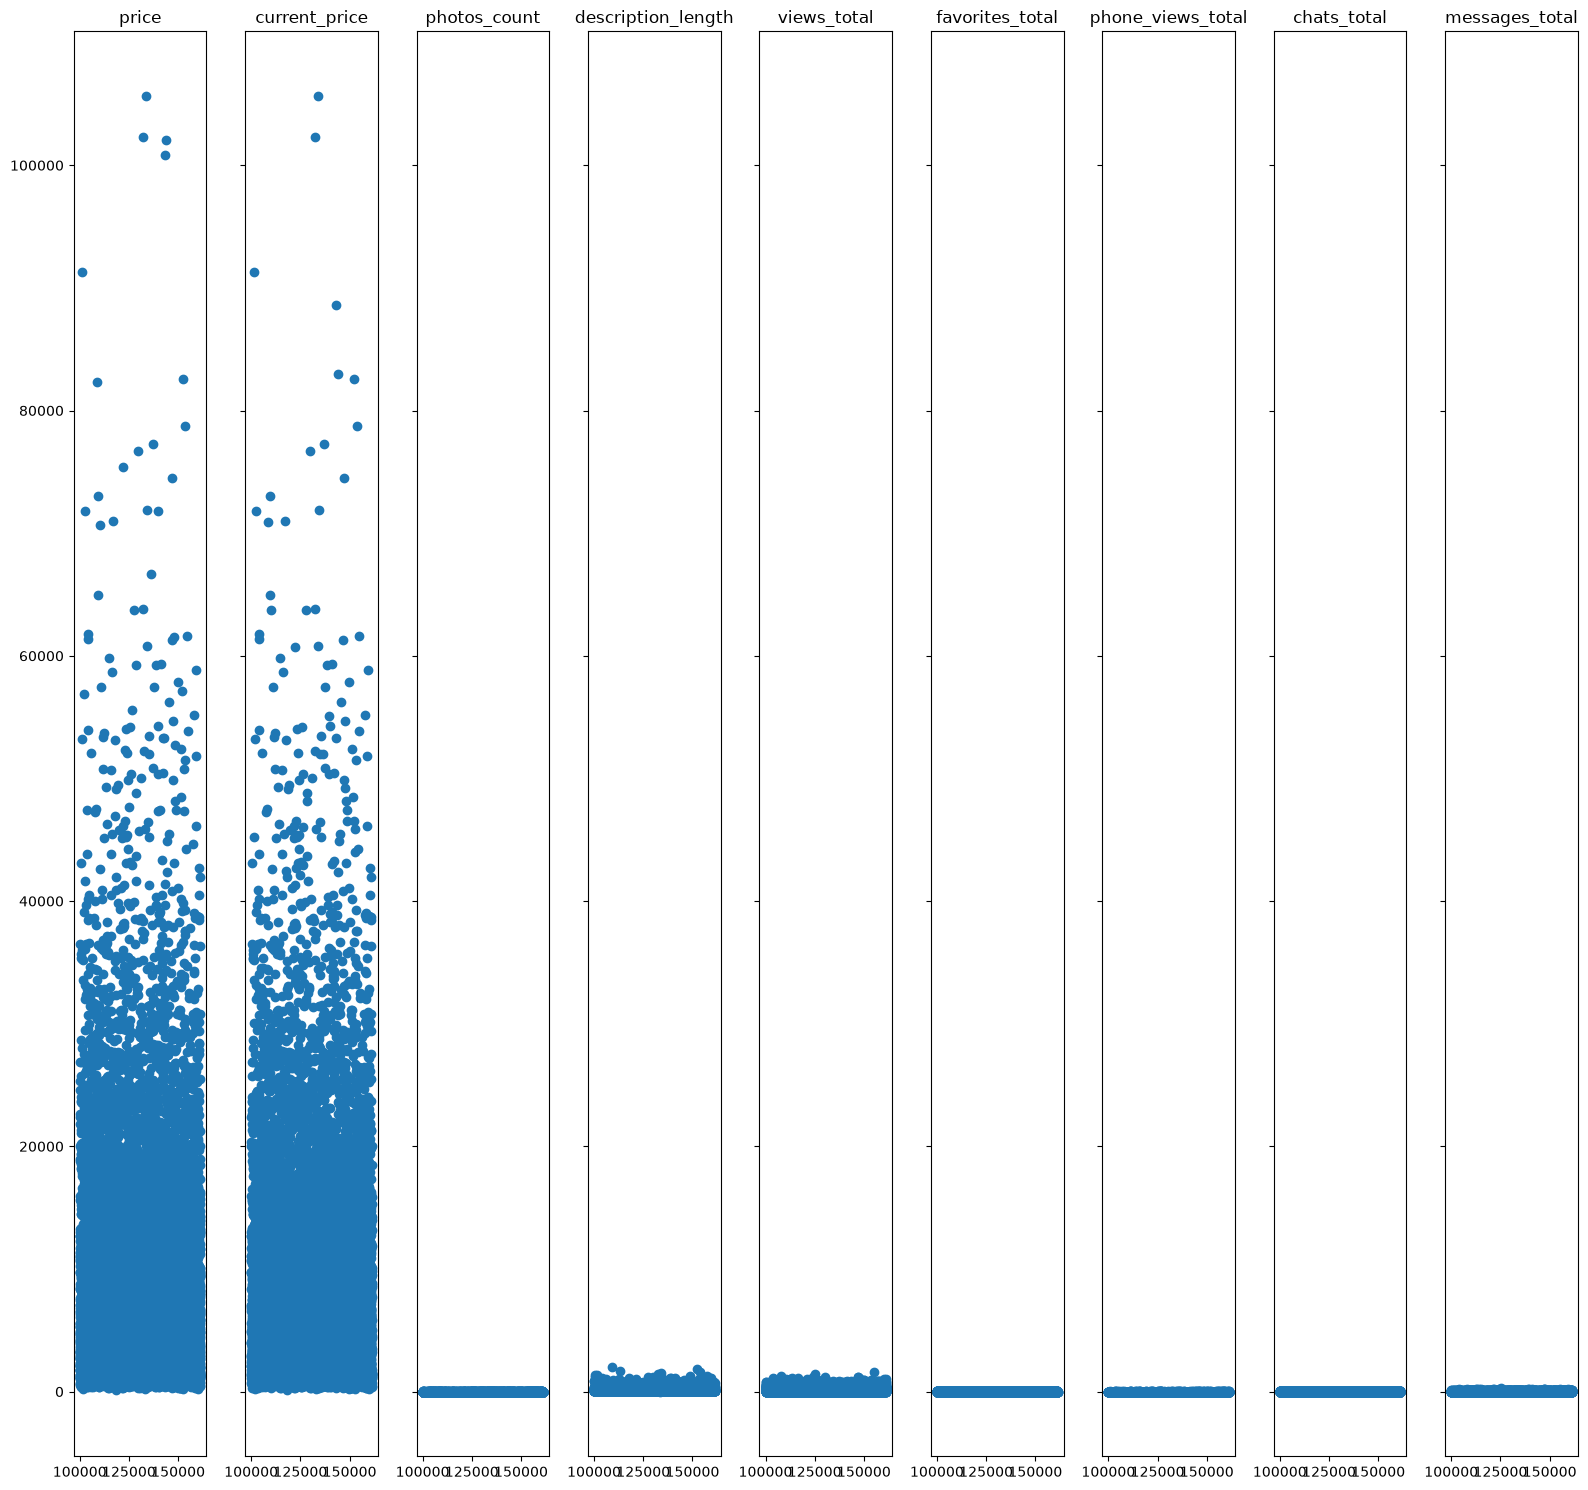

In [119]:
values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]

fig, axes = plt.subplots(
    1, len(values), figsize=(16, 15), sharey=True, squeeze=False
)


for ax, value in zip(axes[0], values):
    y = df[value]

    ax.scatter(df["listing_id"], y)
    ax.set_title(f"{value}")

fig.tight_layout()
plt.show()

### Убираем строчки из всех csvшек, где выбросы по супер большим и по супер малым выбросам, выбросы по времени. Получаем красивые CSV

In [120]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    df = df.drop_duplicates(keep = "first")
    display(file)
    display(df.shape)
    t = df.shape[0]
    df = df[~df["listing_id"].isin(listing_ids_of_bad_time)]
    df = df[~df["listing_id"].isin(low_listing_ids)]
    df = df[~df["listing_id"].isin(indexes_high)]
    display(df.shape)
    display(t - df.shape[0])
    display("--------------------------------------------")
    df.to_csv(f"data/data_wthout_anomailes/{file[:-4]}_wthout_anomailes.csv", index=False, encoding="utf-8")

'events.csv'

(181428, 5)

(178737, 5)

2691

'--------------------------------------------'

'listings.csv'

... (10 outputs left out)

(5942, 4)

(5846, 4)

96

'--------------------------------------------'

### Собираем единый csv со всеми аномалиями

In [121]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    df_1 = df[df["listing_id"].isin(listing_ids_of_bad_time)]
    df_2 = df[df["listing_id"].isin(low_listing_ids)]
    df_3 = df[df["listing_id"].isin(indexes_high)]
    df = pd.concat([df_1, df_2, df_3])
    df = df.drop_duplicates()
    display(file, df.shape)
    display("--------------------------------------------")
    df.to_csv(f"data/data_ONLY_anomailes/{file[:-4]}_ONLY_anomailes.csv", index=False, encoding="utf-8")

'events.csv'

(2691, 5)

'--------------------------------------------'

'listings.csv'

(223, 18)

'--------------------------------------------'

... (2 outputs left out)

'--------------------------------------------'

'surveys.csv'

(96, 4)

'--------------------------------------------'

### Собираем отдельный csv по типам аномалий

In [122]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    df = df[df["listing_id"].isin(low_listing_ids)]
    display(file, df.shape)
    df.to_csv(f"data/data_ONLY_anomailes/anomalies_low_listing_ids/{file[:-4]}_anomalies_low_listing_ids.csv", index=False, encoding="utf-8")

'events.csv'

(954, 5)

'listings.csv'

(86, 18)

'messages.csv'

(1804, 5)

'surveys.csv'

(38, 4)

In [123]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    df = df[df["listing_id"].isin(listing_ids_of_bad_time)]
    display(file, df.shape)
    df.to_csv(f"data/data_ONLY_anomailes/anomalies_bad_time/{file[:-4]}_anomalies_bad_time.csv", index=False, encoding="utf-8")

'events.csv'

(564, 5)

'listings.csv'

(40, 18)

'messages.csv'

(1158, 5)

'surveys.csv'

(20, 4)

In [124]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    df = df[df["listing_id"].isin(indexes_high)]
    display(file, df.shape)
    df.to_csv(f"data/data_ONLY_anomailes/anomalies_high_listing_ids/{file[:-4]}_anomalies_high_listing_ids.csv", index=False, encoding="utf-8")

'events.csv'

(1201, 5)

'listings.csv'

(99, 18)

'messages.csv'

(2397, 5)

'surveys.csv'

(40, 4)